# Pitch control on Metrica tracking data: demo

This notebook walks through the whole pipeline on **Game 2** of Metrica Sports' sample data (a 3–2 Home win):

1. Load tracking and event data
2. Calculate player velocities
3. Compute a pitch-control map for one moment
4. Ask the model about single locations
5. Change the model's parameters
6. Look at the match analysis and validation results

Before running it, download the data with `python scripts/download_data.py` (see the README).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

from pitch_control.config import PitchControlConfig
from pitch_control.loaders import load_match
from pitch_control.model import make_grid, pitch_control_at_frame, pitch_control_at_points
from pitch_control.plotting import add_control_colorbar, home_share, plot_pitch_control
from pitch_control.velocities import add_velocities

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## 1. Load the data

`load_match` turns each sample game into the same structure: positions in **metres**, with the origin on the centre spot. The **Home team always attacks to the right (+x)**, in both halves.

In [2]:
match = load_match(2)
print(f"{len(match.tracking):,} frames at {match.fps} Hz, {len(match.events):,} events")
print("Goalkeepers:", {team: match.goalkeeper(team) for team in ("Home", "Away")})
match.tracking[["Period", "Time [s]", "Home_9_x", "Home_9_y", "Away_25_x", "Away_25_y", "ball_x", "ball_y"]].head()

141,156 frames at 25 Hz, 1,935 events
Goalkeepers: {'Home': '11', 'Away': '25'}


,Period,Time [s],Home_9_x,Home_9_y,Away_25_x,Away_25_y,ball_x,ball_y
Frame,,,,,,,,
1,1,0.04,-0.66885,-13.50684,51.2211,1.19884,NaN,NaN
2,1,0.08,-0.66885,-13.50684,51.2211,1.19884,NaN,NaN
3,1,0.12,-0.66885,-13.50684,51.2211,1.19884,NaN,NaN
4,1,0.16,-0.66885,-13.50684,51.2211,1.19884,NaN,NaN
5,1,0.20,-0.66885,-13.50684,51.2211,1.19884,NaN,NaN


In [3]:
events = match.events
goals = events[(events.type == "SHOT") & events.subtype.str.contains("-GOAL", na=False)]
goals[["team", "period", "start_time", "from", "subtype", "start_x", "start_y"]].assign(
    minute=lambda d: (d.start_time // 60 + 1).astype(int))

,team,period,start_time,from,subtype,start_x,start_y,minute
198,Home,1,488.08,10,ON TARGET-GOAL,47.25,3.40,9
823,Away,1,2121.96,24,ON TARGET-GOAL,-44.10,-2.72,36
1118,Home,2,2959.32,9,HEAD-ON TARGET-GOAL,47.25,-1.36,50
1671,Away,2,4600.36,20,ON TARGET-GOAL,-39.90,-1.36,77
1723,Home,2,4841.08,12,ON TARGET-GOAL,30.45,-5.44,81


## 2. Player velocities

Tracking data only contains positions. Velocities are calculated from changes in position, then cleaned in three ways: a 12 m/s speed cap, Savitzky-Golay smoothing, and a 10 m/s² acceleration limit that removes tracking glitches ([details](../docs/methodology/02_velocities.md)).

In [4]:
tracking = add_velocities(match.tracking, match.fps)
speeds = tracking[[c for c in tracking.columns if c.endswith("_speed")]]
print(f"Median speed {np.nanmedian(speeds):.1f} m/s, 99th percentile {np.nanpercentile(speeds, 99):.1f} m/s, "
      f"max {np.nanmax(speeds):.1f} m/s")

Median speed 1.4 m/s, 99th percentile 6.0 m/s, max 11.3 m/s


## 3. Pitch control for one moment

The model answers one question: *if the ball were played to this spot now, which team would most likely win it?* We ask it for every cell of a grid over the pitch, then colour each cell by the answer.

The moment shown: Home 8 crosses to Home 9, who heads in a goal one second later.

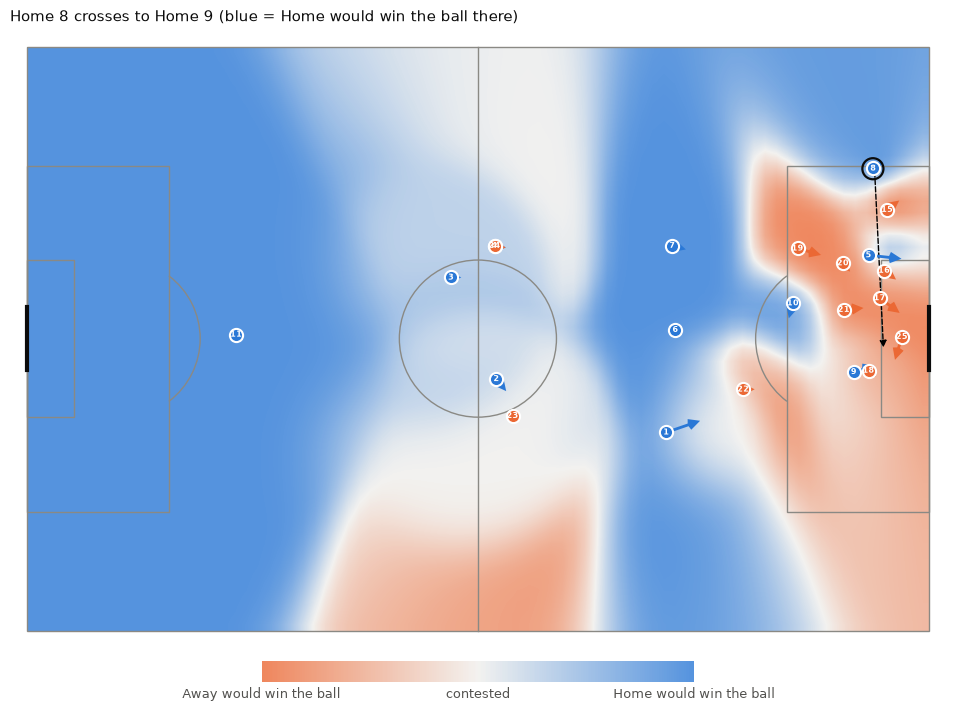

In [5]:
goalkeepers = {team: match.goalkeeper(team) for team in ("Home", "Away")}
cross = events.loc[1116]
frame = int(cross.start_frame)
grid = make_grid(match.pitch, n_x=80)

surface = pitch_control_at_frame(tracking, frame, cross.team, goalkeepers, grid)
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
_, image = plot_pitch_control(surface, tracking.loc[frame], match.pitch, ax=ax,
                              title="Home 8 crosses to Home 9 (blue = Home would win the ball there)")
ax.annotate("", xy=(cross.end_x, cross.end_y), xytext=(cross.start_x, cross.start_y),
            arrowprops=dict(arrowstyle="-|>", color="black", linestyle="--"))
add_control_colorbar(fig, image, ax);

## 4. Asking about single spots

Each pixel above is one answer. We can also ask for specific spots: where Home 9 is standing, and right next to the Away goalkeeper.

In [6]:
row = tracking.loc[frame]
spots = {
    "Home 9's position": (row["Home_9_x"], row["Home_9_y"]),
    "Next to the Away goalkeeper": (row["Away_25_x"] - 1, row["Away_25_y"]),
    "Centre spot": (0.0, 0.0),
}
result = pitch_control_at_points(tracking, frame, "Home", goalkeepers, np.array(list(spots.values())))
pd.DataFrame({"Home control": result.attack.round(3), "Away control": result.defence.round(3)},
             index=list(spots))

,Home control,Away control
Home 9's position,0.308,0.682
Next to the Away goalkeeper,0.076,0.914
Centre spot,0.610,0.382


## 5. Changing the parameters

All the model's parameters are in one place, `PitchControlConfig`. As an example, here's the defender advantage used in Spearman's paper (κ = 1.72, defenders win control faster) compared with the default (κ = 1, both teams equal).

In [7]:
print(PitchControlConfig())

paper = pitch_control_at_frame(tracking, frame, cross.team, goalkeepers, grid, PitchControlConfig(kappa_def=1.72))
change = home_share(paper) - home_share(surface)
print(f"With kappa = 1.72, Home's average control changes by {change.mean():+.3f} "
      f"(largest change at a single point: {change.min():+.3f})")

PitchControlConfig(reaction_time=0.7, max_player_speed=5.0, tti_sigma=0.45, lambda_att=4.3, kappa_def=1.0, gk_factor=3.0, ball_speed=15.0, dt=0.04, max_time=10.0, convergence_tol=0.01, offside=True, offside_tol=0.2, integration='exponential')
With kappa = 1.72, Home's average control changes by -0.065 (largest change at a single point: -0.144)


## 6. Match analysis

`scripts/analyse_match.py` computes these results (about 90 s) and caches them in `outputs/analysis/`. Here we load the cached results.

**Space follows the scoreline:** while the score was level, Home controlled far more of its attacking third than Away did. Once Home led, it reversed.

In [8]:
ft = pd.read_csv(ROOT / "outputs" / "analysis" / "game2_final_third_control.csv")
lead = np.zeros(len(ft))
for g in goals.itertuples():
    lead += np.where(ft.time >= g.start_time, 1 if g.team == "Home" else -1, 0)
ft["score_state"] = np.select([lead > 0, lead < 0], ["Home ahead", "Home behind"], "Level")
(ft.groupby("score_state")[["home_final_third", "away_final_third"]].mean() * 100).round(1) \
    .rename(columns={"home_final_third": "Home controls (%)", "away_final_third": "Away controls (%)"})

,Home controls (%),Away controls (%)
score_state,,
Home ahead,11.6,17.7
Level,19.2,9.2


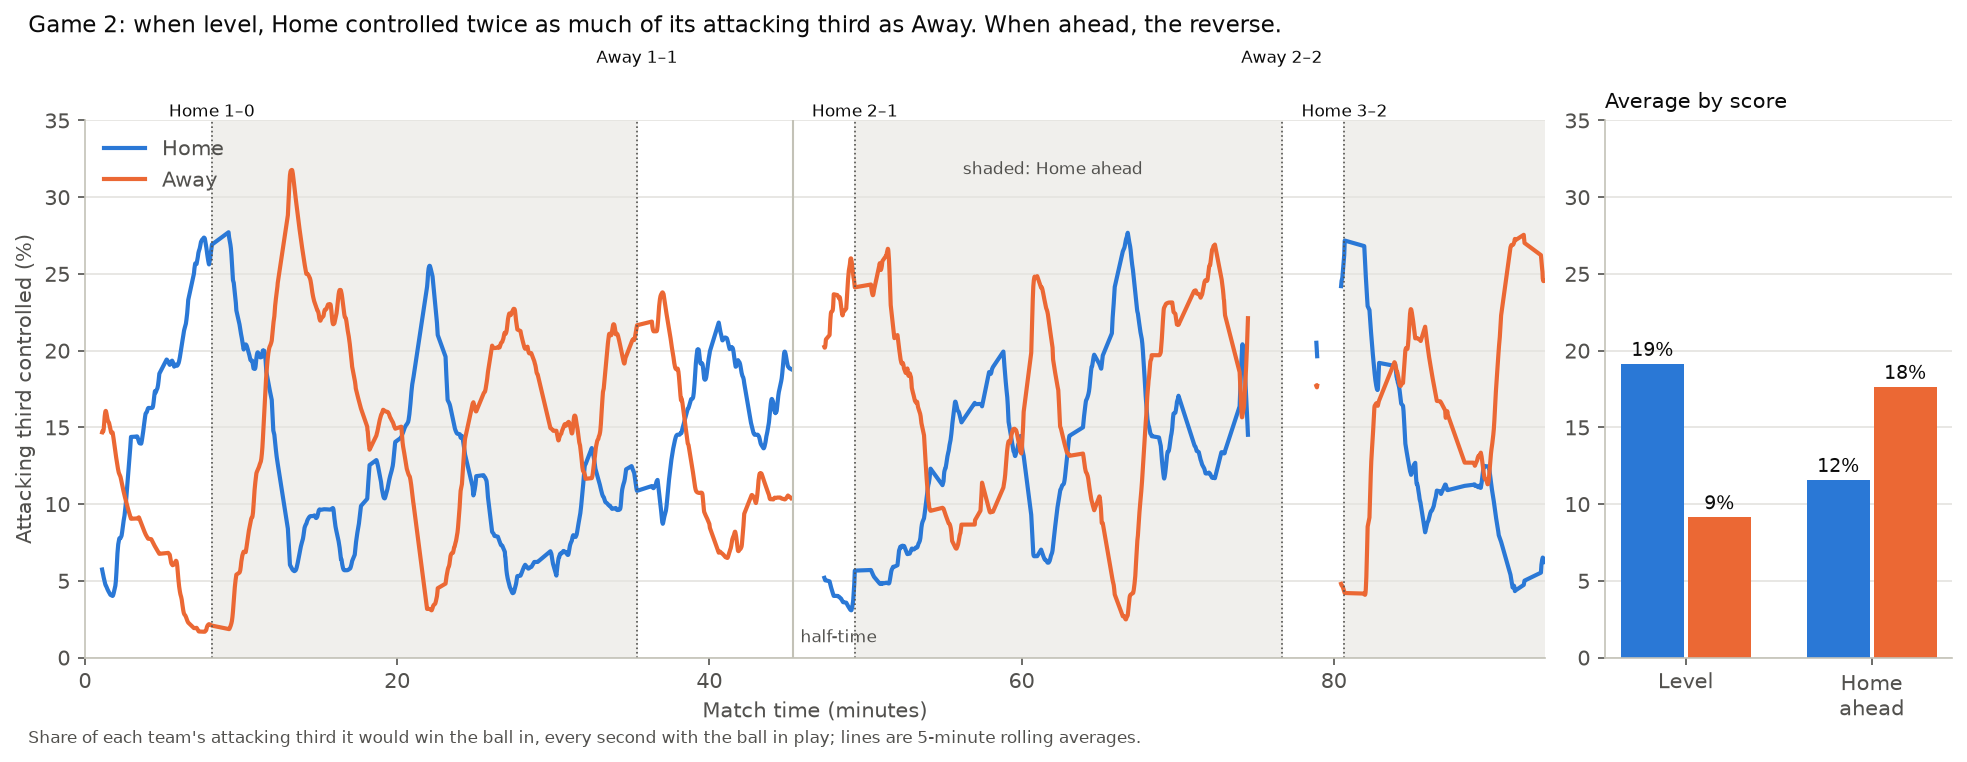

In [9]:
Image(ROOT / "outputs" / "figures" / "final_third_control.png")

**Passes:** the passing team's control at the destination, at the moment of the pass, against whether the pass arrived. The caveat: an intercepted pass is recorded where it was intercepted, which flatters the model ([details](../docs/methodology/06_analysis.md)).

In [10]:
pc = pd.read_csv(ROOT / "outputs" / "analysis" / "game2_pass_control.csv", index_col=0)
bands = pd.cut(pc.target_control, [0, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0001])
pc.groupby(bands, observed=True).completed.agg(passes="size", completed_pct=lambda s: round(100 * s.mean(), 1))

,passes,completed_pct
target_control,,
"(0.0, 0.2]",35,11.4
"(0.2, 0.4]",65,16.9
"(0.4, 0.6]",88,61.4
"(0.6, 0.8]",162,92.0
"(0.8, 0.95]",275,99.3
"(0.95, 1.0]",473,100.0


## 7. Validation

With identical inputs, this implementation matches the Friends of Tracking reference code to within 0.000001, once the reference's speed-up shortcuts are turned off. The remaining differences come from one of those shortcuts, which drops relevant players, and from a more accurate integration step ([details](../docs/methodology/04_validation.md)).

In [11]:
val = pd.read_csv(ROOT / "outputs" / "validation" / "reference_comparison.csv")
val[[c for c in val.columns if c.endswith("_max")]].max().rename("max abs difference over 30 frames").round(6)

1_euler_vs_exact_ref_max              0.000000
2_exponential_vs_exact_ref_max        0.041663
3_published_ref_vs_exact_ref_max      0.112227
4_exponential_vs_published_ref_max    0.107336
Name: max abs difference over 30 frames, dtype: float64

## Animation

`python scripts/animate_goal.py --goal 2` creates an animation of Away's counter-attack goal: [outputs/animations/game2_goal2.gif](../outputs/animations/game2_goal2.gif).